### Downloading and Cleaning Dataset

In [ ]:

!nvidia-smi

Wed Nov  4 15:59:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch

print("PyTorch version:", torch.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected!")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
!pip -q install gdown

!gdown --fuzzy "https://drive.google.com/file/d/1OS1fXwZ1Vsj70lEQajccyssxQRYp5X9D/view?usp=share_link" -O N24News_download

Downloading...
From (original): https://drive.google.com/uc?id=1OS1fXwZ1Vsj70lEQajccyssxQRYp5X9D
From (redirected): https://drive.google.com/uc?id=1OS1fXwZ1Vsj70lEQajccyssxQRYp5X9D&confirm=t&uuid=c0baf9c7-0e12-4e5f-a99f-cc26cafaf0d7
To: /content/N24News_download
 81% 5.68G/7.00G [01:29<00:14, 94.4MB/s]^C


In [ ]:
!ls -lh
!file N24News_download

total 12G
drwxr-xr-x 3 root root 4.0K Nov  4 15:43 bert_news_results
drwxr-xr-x 4 root root 4.0K Nov  4 15:08 dataset
-rw-r--r-- 1 root root 6.6G Jul  5  2022 N24News_download
-rw-r--r-- 1 root root 5.3G Nov  4 16:00 N24News_downloadzva1xpta.part
drwxr-xr-x 1 root root 4.0K Oct 21 13:28 sample_data
N24News_download: Zip archive data, at least v2.0 to extract, compression method=store


In [ ]:
import zipfile
import os

zip_path = "N24News_download"
extract_path = "/content/dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

KeyboardInterrupt: 

In [ ]:
import os

extract_path = "/content/dataset"

for root, dirs, files in os.walk(extract_path):

    print("\nFolder:", root)

    for file in files[:10]:
        print("   ", file)

    if root.count(os.sep) - extract_path.count(os.sep) >= 2:
        dirs.clear()


Folder: /content/dataset

Folder: /content/dataset/news
    nytimes_origin.json
    leftovers.json
    nytimes.json
    nytimes_dataset.json
    nytimes_test.json
    nytimes_dev.json
    nytimes_train.json

Folder: /content/dataset/imgs
    c259de44-7e5c-517f-81ed-6e79bbf4149f.jpg
    b225aced-f482-55ab-a1e5-2ae0628ec5ea.jpg
    d6586e71-6d59-5390-a449-b9436ee9bb1b.jpg
    3a9a4056-e9bd-5141-ae3d-94ef10db36e5.jpg
    221aea3f-c2c1-5de8-b25c-d9a3f9fb2337.jpg
    c80f2721-1941-50a1-af69-33f1103ede3e.jpg
    c1b5a62c-1c36-5740-b0fe-5422a66ba81c.jpg
    efa66920-e713-580e-9a7e-690e91009ef3.jpg
    f40642c6-ce70-5326-9628-148e9192827a.jpg
    6eb23c8e-4b61-5013-9668-2da9efc6bb6a.jpg


In [ ]:
import os
import json

news_path = "/content/dataset/news"

# Check file sizes
for file in os.listdir(news_path):
    path = os.path.join(news_path, file)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"{file}: {size_mb:.2f} MB")

nytimes_origin.json: 329.04 MB
leftovers.json: 5.49 MB
nytimes.json: 323.40 MB
nytimes_dataset.json: 43.30 MB
nytimes_test.json: 32.36 MB
nytimes_dev.json: 32.07 MB
nytimes_train.json: 258.98 MB


In [ ]:
file_path = os.path.join(news_path, "nytimes_train.json")

with open(file_path, "r", encoding="utf-8") as f:
    content = f.read(5000)

print(content)

[{"section": "Theater", "headline": "Before 'Moonlight' and 'The Walking Dead,' a Friendship Born in the Classroom", "article_url": "https://www.nytimes.com/2017/02/21/theater/danai-gurira-andre-holland-walking-dead.html", "article": "Danai Gurira and Andre Holland in a theater at New York University, where they met in the Tisch Graduate Acting Program.\n\nBehind every successful person are relationships that helped forge a path. But the stories of these friendships, collaborations, alliances, romances or rivalries often are lost in the glow of achievement. In this new feature, we explore a personal connection that made a difference in the lives of two artists. Andre Holland never thought much about writing his own monologues when he attended the Tisch graduate acting program at New York University. But one day, early in his first semester in 2003, he watched another African-American student, Danai Gurira, forgo the usual speeches by white characters and perform her own material instea

In [ ]:
import pandas as pd
import os

news_path = "/content/dataset/news"

train_df = pd.read_json(
    os.path.join(news_path, "nytimes_train.json")
)

dev_df = pd.read_json(
    os.path.join(news_path, "nytimes_dev.json")
)

test_df = pd.read_json(
    os.path.join(news_path, "nytimes_test.json")
)

print("Training data:", train_df.shape)
print("Validation data:", dev_df.shape)
print("Testing data:", test_df.shape)

Training data: (48988, 9)
Validation data: (6123, 9)
Testing data: (6124, 9)


In [ ]:
print("Number of categories:",
      train_df['section'].nunique())

print("\nCategory distribution:")
print(train_df['section'].value_counts())

Number of categories: 24

Category distribution:
section
Opinion            2437
Art & Design       2431
Television         2419
Music              2416
Real Estate        2413
Travel             2413
Books              2412
Theater            2409
Health             2409
Sports             2407
Science            2387
Fashion & Style    2385
Food               2385
Movies             2384
Technology         2376
Dance              2365
Media              2363
Style              2147
Automobiles        1456
Economy            1398
Your Money         1020
Global Business     955
Education           672
Well                529
Name: count, dtype: int64


In [ ]:
print(train_df.isnull().sum())

section        0
headline       0
article_url    0
article        0
abstract       0
article_id     0
image          0
caption        0
image_id       0
dtype: int64


In [ ]:
pd.set_option('display.max_colwidth', 150)

display(
    train_df[['section', 'headline', 'article']].head(5)
)

,section,headline,article
0,Theater,"Before 'Moonlight' and 'The Walking Dead,' a Friendship Born in the Classroom","Danai Gurira and Andre Holland in a theater at New York University, where they met in the Tisch Graduate Acting Program.\n\nBehind every successfu..."
1,Television,What's on TV Wednesday: 'Crip Camp' and 'Dark Phoenix',"CRIP CAMP: A DISABILITY REVOLUTION (2020) Stream on Netflix. This documentary, the latest offering from Barack Obama and Michelle Obama's producti..."
2,Sports,Rays Stick to Their Plan and Reach a 2nd World Series,"The Tampa Bay Rays told Charlie Morton it would happen. When they chased him as a free agent before last season, their front office did not presen..."
3,Art & Design,"For Robert Rauschenberg, No Artist Is an Island","We tend to think of artists as natural loners, off in their studios, wrestling with their inner selves. But ""Robert Rauschenberg: Among Friends,"" ..."
4,Theater,Jimmy Buffett's 'Margaritaville' Musical Sets Broadway Opening,"Jimmy Buffett's tropical paradise will land in a chilly New York this winter with the opening of the musical ""Escape to Margaritaville"" on Broadwa..."


In [ ]:
print("Duplicate training articles:",
      train_df.duplicated(
          subset=['headline', 'article']
      ).sum())

print("Duplicate validation articles:",
      dev_df.duplicated(
          subset=['headline', 'article']
      ).sum())

print("Duplicate testing articles:",
      test_df.duplicated(
          subset=['headline', 'article']
      ).sum())

Duplicate training articles: 4
Duplicate validation articles: 0
Duplicate testing articles: 0


In [ ]:
train_df['text'] = (
    train_df['headline'] + " " + train_df['article']
)

dev_df['text'] = (
    dev_df['headline'] + " " + dev_df['article']
)

test_df['text'] = (
    test_df['headline'] + " " + test_df['article']
)

print(train_df['text'].iloc[0][:1000])

Before 'Moonlight' and 'The Walking Dead,' a Friendship Born in the Classroom Danai Gurira and Andre Holland in a theater at New York University, where they met in the Tisch Graduate Acting Program.

Behind every successful person are relationships that helped forge a path. But the stories of these friendships, collaborations, alliances, romances or rivalries often are lost in the glow of achievement. In this new feature, we explore a personal connection that made a difference in the lives of two artists. Andre Holland never thought much about writing his own monologues when he attended the Tisch graduate acting program at New York University. But one day, early in his first semester in 2003, he watched another African-American student, Danai Gurira, forgo the usual speeches by white characters and perform her own material instead. Her monologue, about the struggles of black women, had an immediacy and ferocity that led to a bond between them -- as friends, actors and, eventually, writ

In [ ]:
print("Before:", train_df.shape)

train_df = train_df.drop_duplicates(
    subset=['headline', 'article']
).reset_index(drop=True)

print("After:", train_df.shape)

Before: (48988, 10)
After: (48984, 10)


In [ ]:
train_ids = set(train_df['article_id'])
dev_ids = set(dev_df['article_id'])
test_ids = set(test_df['article_id'])

print("Train-Test overlap:", len(train_ids & test_ids))
print("Train-Validation overlap:", len(train_ids & dev_ids))
print("Validation-Test overlap:", len(dev_ids & test_ids))

Train-Test overlap: 0
Train-Validation overlap: 0
Validation-Test overlap: 0


In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()


train_df['clean_text'] = train_df['text'].apply(clean_text)
dev_df['clean_text'] = dev_df['text'].apply(clean_text)
test_df['clean_text'] = test_df['text'].apply(clean_text)

print("Original text:")
print(train_df['text'].iloc[0][:300])

print("\nCleaned text:")
print(train_df['clean_text'].iloc[0][:300])

NameError: name 'train_df' is not defined

In [ ]:
X_train = train_df['clean_text']
y_train = train_df['section']

X_val = dev_df['clean_text']
y_val = dev_df['section']

X_test = test_df['clean_text']
y_test = test_df['section']

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (48984,) (48984,)
Validation: (6123,) (6123,)
Testing: (6124,) (6124,)


### Training Tradition ML Models

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

# Learn vocabulary and transform training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and testing data
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Validation shape:", X_val_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

NameError: name 'X_train' is not defined

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Create model
nb_model = MultinomialNB()

# Train model
nb_model.fit(X_train_tfidf, y_train)

# Predict validation data
nb_val_pred = nb_model.predict(X_val_tfidf)

# Evaluate
print("Validation Accuracy:",
      accuracy_score(y_val, nb_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, nb_val_pred))

Validation Accuracy: 0.8232892373019761

Classification Report:
                 precision    recall  f1-score   support

   Art & Design       0.81      0.92      0.86       257
    Automobiles       0.97      0.93      0.95       196
          Books       0.83      0.83      0.83       284
          Dance       0.97      0.97      0.97       318
        Economy       0.78      0.85      0.82       180
      Education       0.88      0.54      0.67        79
Fashion & Style       0.73      0.76      0.75       309
           Food       0.90      0.87      0.89       326
Global Business       0.91      0.68      0.78       127
         Health       0.69      0.90      0.78       285
          Media       0.80      0.86      0.83       312
         Movies       0.87      0.78      0.83       325
          Music       0.86      0.90      0.88       299
        Opinion       0.73      0.77      0.75       280
    Real Estate       0.82      0.92      0.87       289
        Science       0

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

nb_accuracy = accuracy_score(y_val, nb_val_pred)

nb_precision, nb_recall, nb_f1, _ = (
    precision_recall_fscore_support(
        y_val,
        nb_val_pred,
        average='weighted',
        zero_division=0
    )
)

results = []

results.append({
    "Model": "Naive Bayes",
    "Accuracy": nb_accuracy,
    "Precision": nb_precision,
    "Recall": nb_recall,
    "F1-Score": nb_f1
})

print(results)

[{'Model': 'Naive Bayes', 'Accuracy': 0.8232892373019761, 'Precision': 0.8140095625871111, 'Recall': 0.8232892373019761, 'F1-Score': 0.8151139715786817}]


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(
    max_iter=1000,
    C=1.0,
    random_state=42
)

# Training
lr_model.fit(X_train_tfidf, y_train)

# Validation predictions
lr_val_pred = lr_model.predict(X_val_tfidf)

# Evaluation
print("Validation Accuracy:",
      accuracy_score(y_val, lr_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    lr_val_pred,
    zero_division=0
))

Validation Accuracy: 0.8672219500244978

Classification Report:
                 precision    recall  f1-score   support

   Art & Design       0.84      0.91      0.88       257
    Automobiles       0.94      0.95      0.95       196
          Books       0.87      0.88      0.87       284
          Dance       0.97      0.98      0.97       318
        Economy       0.90      0.86      0.88       180
      Education       0.79      0.72      0.75        79
Fashion & Style       0.77      0.75      0.76       309
           Food       0.90      0.91      0.91       326
Global Business       0.89      0.84      0.87       127
         Health       0.80      0.86      0.83       285
          Media       0.85      0.88      0.86       312
         Movies       0.89      0.91      0.90       325
          Music       0.91      0.94      0.92       299
        Opinion       0.84      0.82      0.83       280
    Real Estate       0.90      0.91      0.91       289
        Science       0

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

svm_model = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=2000
)

# Training
svm_model.fit(X_train_tfidf, y_train)

# Validation predictions
svm_val_pred = svm_model.predict(X_val_tfidf)

# Evaluation
print("Validation Accuracy:",
      accuracy_score(y_val, svm_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    svm_val_pred,
    zero_division=0
))

Validation Accuracy: 0.8793075289890576

Classification Report:
                 precision    recall  f1-score   support

   Art & Design       0.86      0.93      0.89       257
    Automobiles       0.94      0.96      0.95       196
          Books       0.87      0.87      0.87       284
          Dance       0.97      0.99      0.98       318
        Economy       0.94      0.89      0.91       180
      Education       0.81      0.80      0.80        79
Fashion & Style       0.74      0.76      0.75       309
           Food       0.94      0.93      0.93       326
Global Business       0.90      0.90      0.90       127
         Health       0.81      0.86      0.83       285
          Media       0.87      0.91      0.89       312
         Movies       0.91      0.89      0.90       325
          Music       0.91      0.96      0.93       299
        Opinion       0.89      0.86      0.87       280
    Real Estate       0.90      0.96      0.93       289
        Science       0

In [ ]:
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

GPU Available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


### Loading BERT and fine-tuning it

In [ ]:
!pip -q install transformers datasets accelerate

In [ ]:
import torch
import numpy as np
import pandas as pd

from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    TrainingArguments,
    Trainer
)

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
CUDA: True


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

train_df['label'] = label_encoder.fit_transform(train_df['section'])
dev_df['label'] = label_encoder.transform(dev_df['section'])
test_df['label'] = label_encoder.transform(test_df['section'])

num_labels = len(label_encoder.classes_)

print("Number of categories:", num_labels)
print("\nCategory mapping:")

for i, category in enumerate(label_encoder.classes_):
    print(i, ":", category)

Number of categories: 24

Category mapping:
0 : Art & Design
1 : Automobiles
2 : Books
3 : Dance
4 : Economy
5 : Education
6 : Fashion & Style
7 : Food
8 : Global Business
9 : Health
10 : Media
11 : Movies
12 : Music
13 : Opinion
14 : Real Estate
15 : Science
16 : Sports
17 : Style
18 : Technology
19 : Television
20 : Theater
21 : Travel
22 : Well
23 : Your Money


In [ ]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained(
    "bert-base-uncased"
)

print("BERT tokenizer loaded successfully!")

BERT tokenizer loaded successfully!


In [ ]:
from datasets import Dataset

# Convert Pandas DataFrames into Hugging Face datasets
train_dataset = Dataset.from_pandas(
    train_df[['text', 'label']]
)

val_dataset = Dataset.from_pandas(
    dev_df[['text', 'label']]
)

test_dataset = Dataset.from_pandas(
    test_df[['text', 'label']]
)

# Tokenization function
def tokenize_function(examples):
    return tokenizer(
        examples['text'],
        padding='max_length',
        truncation=True,
        max_length=384
    )

# Tokenize all datasets
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

print("Tokenization completed!")

Map:   0%|          | 0/48984 [00:00<?, ? examples/s]

Map:   0%|          | 0/6123 [00:00<?, ? examples/s]

Map:   0%|          | 0/6124 [00:00<?, ? examples/s]

Tokenization completed!


In [ ]:
# Rename label column to labels
train_dataset = train_dataset.rename_column("label", "labels")
val_dataset = val_dataset.rename_column("label", "labels")
test_dataset = test_dataset.rename_column("label", "labels")

# Keep only columns required by BERT
columns = [
    'input_ids',
    'attention_mask',
    'token_type_ids',
    'labels'
]

train_dataset.set_format(
    type='torch',
    columns=columns
)

val_dataset.set_format(
    type='torch',
    columns=columns
)

test_dataset.set_format(
    type='torch',
    columns=columns
)

print("Dataset preparation completed!")
print("Input shape:", train_dataset[0]['input_ids'].shape)
print("Label:", train_dataset[0]['labels'])

Dataset preparation completed!
Input shape: torch.Size([384])
Label: tensor(20)


In [ ]:
from transformers import BertForSequenceClassification

model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=24
)

# Move model to GPU
model.to("cuda")

print("BERT model loaded successfully!")
print("Model device:", next(model.parameters()).device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded successfully!
Model device: cuda:0


In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average='weighted',
        zero_division=0
    )

    _, _, macro_f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average='macro',
        zero_division=0
    )

    return {
        'accuracy': accuracy_score(labels, predictions),
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'macro_f1': macro_f1
    }

print("Evaluation metrics configured!")

Evaluation metrics configured!


In [ ]:
import transformers
import inspect

print("Transformers version:", transformers.__version__)
print(inspect.signature(TrainingArguments.__init__))

Transformers version: 5.22.1
(self, output_dir: str | None = None, per_device_train_batch_size: int = 8, num_train_epochs: float = 3.0, max_steps: int = -1, learning_rate: float = 5e-05, lr_scheduler_type: transformers.trainer_utils.SchedulerType | str = 'linear', lr_scheduler_kwargs: dict | str | None = None, warmup_steps: float = 0, optim: transformers.training_args.OptimizerNames | str = 'adamw_torch_fused', optim_args: str | None = None, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, optim_target_modules: None | str | list[str] = None, gradient_accumulation_steps: int = 1, average_tokens_across_devices: bool = True, max_grad_norm: float = 1.0, label_smoothing_factor: float = 0.0, bf16: bool = False, fp16: bool = False, bf16_full_eval: bool = False, fp16_full_eval: bool = False, tf32: bool | None = None, gradient_checkpointing: bool = False, gradient_checkpointing_kwargs: dict[str, typing.Any] | str | None = None, torch_co

In [ ]:
import math
from transformers import TrainingArguments, Trainer

# Calculate warmup steps (10% of total training steps)
steps_per_epoch = math.ceil(
    len(train_dataset) / (8 * 2)
)
total_steps = steps_per_epoch * 3
warmup_steps = int(total_steps * 0.1)

training_args = TrainingArguments(

    output_dir="./bert_news_results",

    num_train_epochs=3,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,

    learning_rate=1e-5,
    weight_decay=0.01,

    warmup_steps=warmup_steps,
    lr_scheduler_type="linear",

    eval_strategy="epoch",
    save_strategy="epoch",

    logging_steps=100,

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=1,

    max_grad_norm=1.0,
    seed=42,

    fp16=True,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

print("BERT Trainer configured successfully!")
print("Total training steps:", total_steps)
print("Warmup steps:", warmup_steps)

BERT Trainer configured successfully!
Total training steps: 9186
Warmup steps: 918


In [ ]:
training_output = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1
1,0.920406,0.515612,0.848440,0.848544,0.848440,0.845547,0.818942
2,0.769627,0.439463,0.869182,0.871620,0.869182,0.869549,0.851080


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1
1,0.920406,0.515612,0.848440,0.848544,0.848440,0.845547,0.818942
2,0.769627,0.439463,0.869182,0.871620,0.869182,0.869549,0.851080
3,0.450890,0.445290,0.871305,0.871415,0.871305,0.870956,0.852884


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

In [ ]:
# Evaluate the currently loaded best model
bert_val_results = trainer.evaluate()

print(bert_val_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Macro F1
0.450890,0.445290,3,0.871305,0.871415,0.871305,0.870956,0.852884


{'eval_loss': 0.4452901780605316, 'eval_accuracy': 0.8713049158909032, 'eval_precision': 0.8714150532073525, 'eval_recall': 0.8713049158909032, 'eval_f1': 0.8709557314798728, 'eval_macro_f1': 0.8528840128306078}


In [ ]:
from sklearn.metrics import classification_report
import numpy as np

bert_val_output = trainer.predict(val_dataset)

bert_val_pred = np.argmax(
    bert_val_output.predictions,
    axis=1
)

print(classification_report(
    dev_df['label'],       # Numerical actual labels
    bert_val_pred,         # Numerical predictions
    target_names=label_encoder.classes_,
    zero_division=0
))

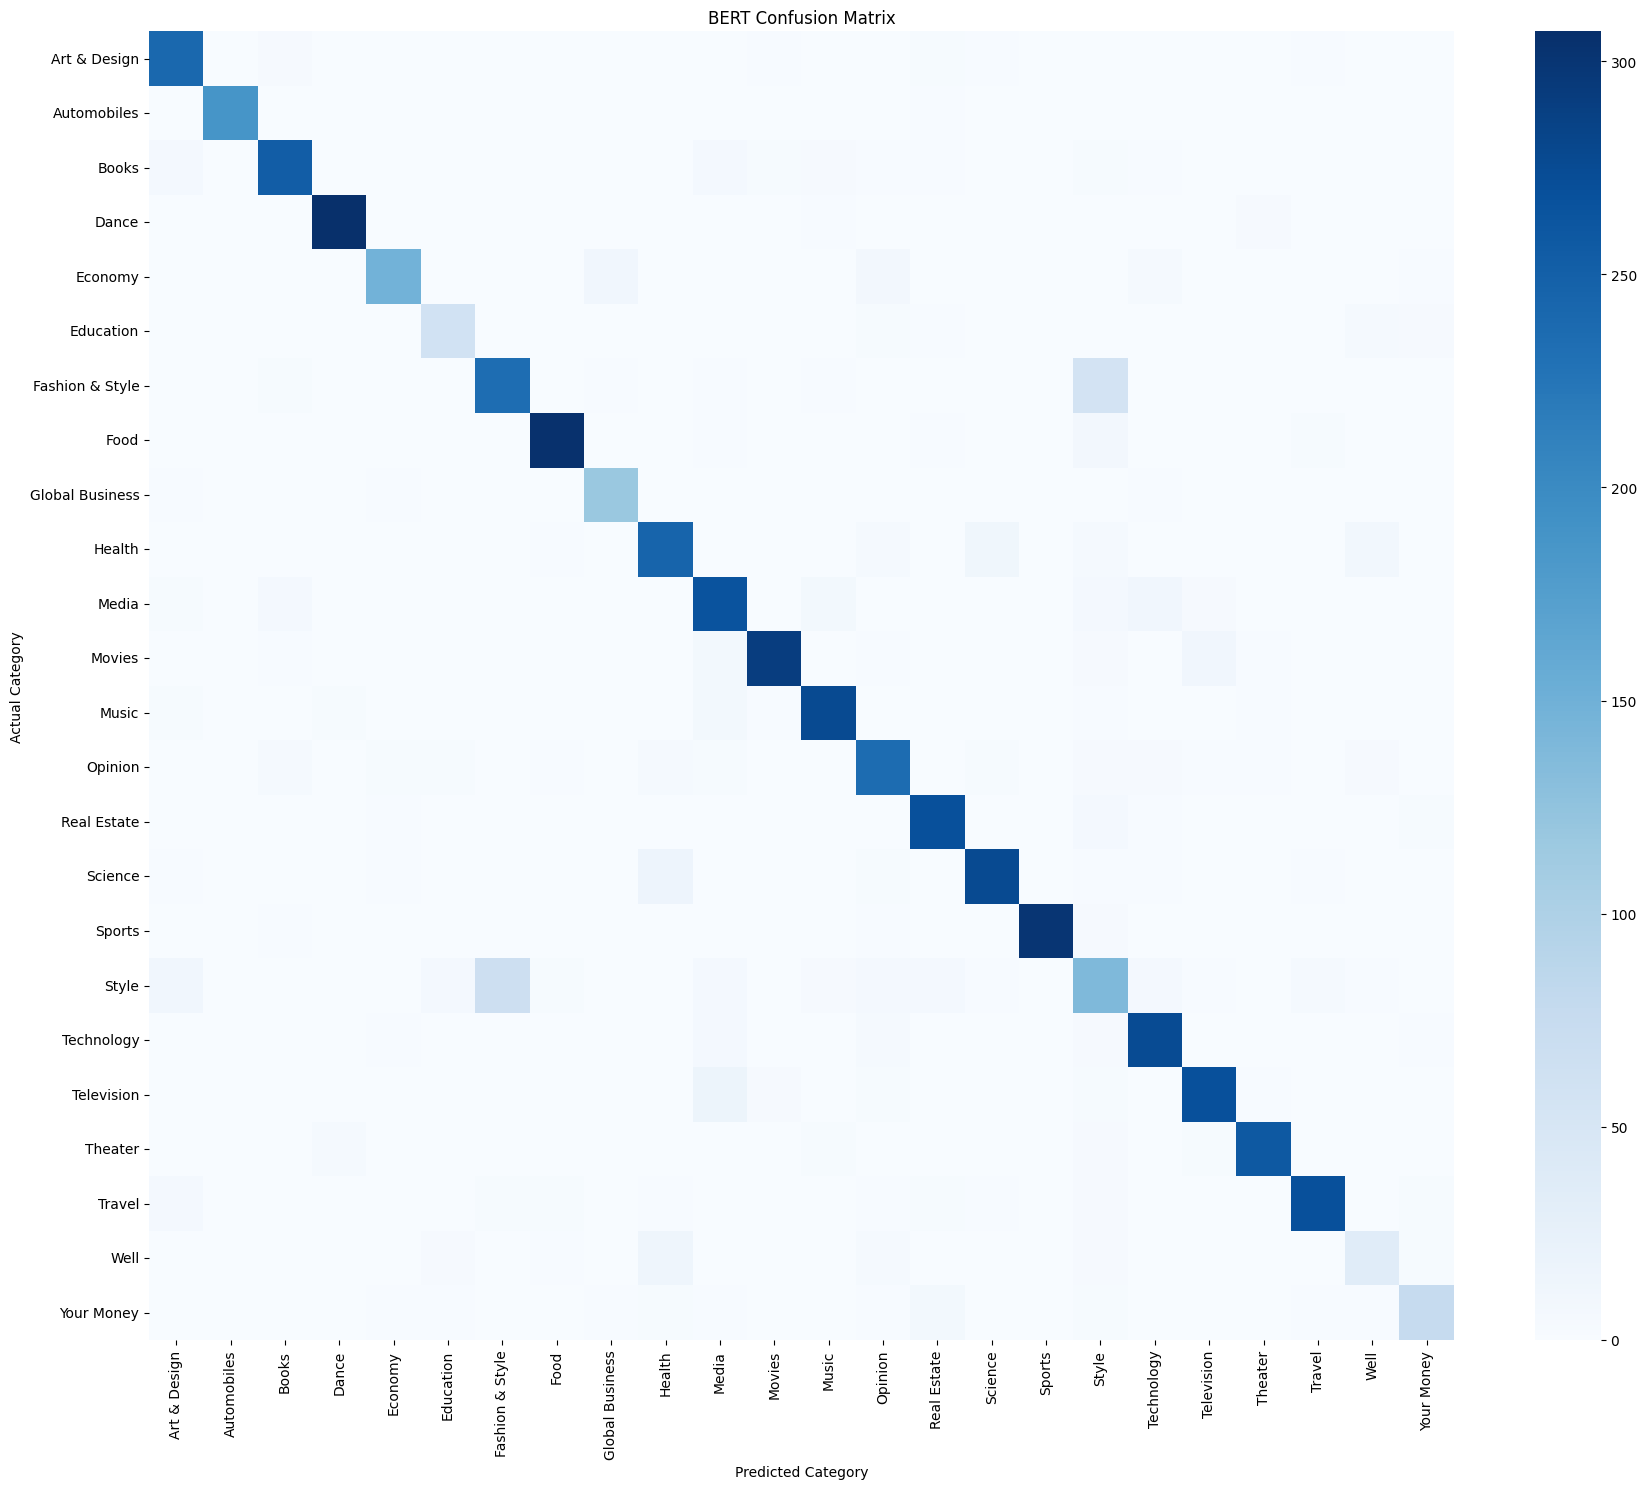

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    dev_df['label'],
    bert_val_pred
)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("BERT Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Results

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd
import numpy as np

final_results = []

def evaluate_model(name, actual, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual, predicted,
        average='weighted',
        zero_division=0
    )

    _, _, macro_f1, _ = precision_recall_fscore_support(
        actual, predicted,
        average='macro',
        zero_division=0
    )

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision,
        "Recall": recall,
        "Weighted F1": f1,
        "Macro F1": macro_f1
    })

# Traditional ML predictions
nb_test_pred = nb_model.predict(X_test_tfidf)
lr_test_pred = lr_model.predict(X_test_tfidf)
svm_test_pred = svm_model.predict(X_test_tfidf)

# BERT predictions
bert_test_output = trainer.predict(test_dataset)
bert_test_pred = np.argmax(
    bert_test_output.predictions,
    axis=1
)

# Evaluate all models
evaluate_model("Naive Bayes", test_df['section'], nb_test_pred)
evaluate_model("Logistic Regression", test_df['section'], lr_test_pred)
evaluate_model("Linear SVM", test_df['section'], svm_test_pred)
evaluate_model("BERT", test_df['label'], bert_test_pred)

# Display comparison
comparison_df = pd.DataFrame(final_results)
print(comparison_df.round(4).to_string(index=False))

### Working Final Product

In [ ]:
import torch
import ipywidgets as widgets
import re
from IPython.display import display, HTML, clear_output

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Input fields
headline_input = widgets.Text(
    placeholder="Enter news headline...",
    description="Headline:",
    layout=widgets.Layout(width="100%"),
    style={"description_width": "90px"}
)

article_input = widgets.Textarea(
    placeholder="Paste the complete news article here...",
    description="Article:",
    layout=widgets.Layout(width="100%", height="180px"),
    style={"description_width": "90px"}
)

classify_button = widgets.Button(
    description="Classify News",
    button_style="primary",
    icon="search",
    layout=widgets.Layout(width="180px", height="40px")
)

output = widgets.Output()

# Prediction function
def classify_news_ui(b):

    with output:
        clear_output()

        headline = headline_input.value.strip()
        article = article_input.value.strip()

        if not headline or not article:
            display(HTML(
                "<p style='color:red;'>Please enter both headline and article.</p>"
            ))
            return

        text = headline + " " + article

        # Traditional ML predictions
        cleaned_text = clean_text(text)
        tfidf_input = tfidf.transform([cleaned_text])

        nb_pred = nb_model.predict(tfidf_input)[0]
        lr_pred = lr_model.predict(tfidf_input)[0]
        svm_pred = svm_model.predict(tfidf_input)[0]

        # BERT prediction
        encoding = tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=384,
            return_tensors="pt"
        )

        device = next(model.parameters()).device
        encoding = {
            k: v.to(device) for k, v in encoding.items()
        }

        model.eval()

        with torch.no_grad():
            logits = model(**encoding).logits
            bert_label = torch.argmax(logits, dim=1).item()

        bert_pred = label_encoder.inverse_transform([bert_label])[0]

        predictions = {
            "Naive Bayes": nb_pred,
            "Logistic Regression": lr_pred,
            "Linear SVM": svm_pred,
            "BERT": bert_pred
        }

        # Count agreement
        from collections import Counter
        counts = Counter(predictions.values())
        majority_category, votes = counts.most_common(1)[0]

        # Display headline
        display(HTML(f"""
        <div style="background:#172554; color:white; padding:18px;
                    border-radius:10px; margin-top:15px;">
            <h3 style="margin:0; color:white;">News Classification Results</h3>
            <p style="margin:8px 0 0;">{headline}</p>
        </div>
        """))

        # Prediction table
        rows = ""

        for name, category in predictions.items():
            rows += f"""
            <tr>
                <td style="padding:12px; border-bottom:1px solid #ddd;">
                    <b>{name}</b>
                </td>
                <td style="padding:12px; border-bottom:1px solid #ddd;">
                    {category}
                </td>
            </tr>
            """

        display(HTML(f"""
        <table style="width:100%; border-collapse:collapse;
                      margin-top:15px; font-size:14px;">
            <tr style="background:#334155; color:white;">
                <th style="padding:12px; text-align:left;">Model</th>
                <th style="padding:12px; text-align:left;">Predicted Category</th>
            </tr>
            {rows}
        </table>
        """))

        # Agreement summary
        display(HTML(f"""
        <div style="background:#f1f5f9; color:#172554;
                    padding:15px; border-radius:10px; margin-top:15px;">
            <b>Model Agreement</b><br>
            {votes} out of 4 models predicted:
            <b>{majority_category}</b>
        </div>
        """))

# Button action
classify_button.on_click(classify_news_ui)

# Display interface
display(HTML("""
<h2 style="color:#2563eb;">AI-Powered News Classification</h2>
<p>Compare predictions from four Machine Learning and Deep Learning models.</p>
"""))

display(headline_input)
display(article_input)
display(classify_button)
display(output)

Text(value='', description='Headline:', layout=Layout(width='100%'), placeholder='Enter news headline...', sty…

Textarea(value='', description='Article:', layout=Layout(height='180px', width='100%'), placeholder='Paste the…

Button(button_style='primary', description='Classify News', icon='search', layout=Layout(height='40px', width=…

Output()